# Mini-Project 2 — Solar Micro-Grid Dispatch Planner

**Scenario.** A rural health centre in Kasese must decide each day how much energy to draw from solar panels ($x$, kWh) and batteries ($y$, kWh) so that two demand constraints hold:

$$3x + 2y = D_1 \quad\text{(daytime load)}, \qquad 4x + y = D_2 \quad\text{(critical-equipment load)}$$

**Assumptions**
- Demand is in kWh per day. The 30-day demand file is **synthetic** (seeded): $D_1 \approx 110$ kWh at weekends and $\approx 125$ kWh on weekdays (outpatient clinics), and $D_2 \approx 138$ kWh with a mild weekly cycle (fridges, oxygen concentrators, theatre). Both include random noise.
- Prices are illustrative: solar UGX 150/kWh, battery UGX 450/kWh.
- A day is *physically infeasible* if the exact solution needs a negative amount of energy from any source.

Code: `src/microgrid.py` (classes `MicroGrid`, `HybridMicroGrid`, `DispatchResult`, `Tariff`).

In [1]:
import statistics
import timeit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.microgrid import (
    MicroGrid, HybridMicroGrid, Tariff, generate_demand_csv, load_demand_csv,
    prompt_day_demand,
)

SEED = 2026
pd.set_option("display.float_format", "{:,.2f}".format)

## Task 1 — The `MicroGrid` class and a well-posedness check

In [2]:
grid = MicroGrid()
print(grid)
pd.Series(grid.diagnostics(), name="value").to_frame()

MicroGrid(sources=('solar', 'battery'), A=[[3.0, 2.0], [4.0, 1.0]])


,value
determinant,-5.00
condition_number,5.83
rank,2
well_posed,True


**Determinant.** $\det A = 3\cdot1 - 2\cdot4 = -5 \neq 0$, so $A$ is invertible and **every** pair $(D_1, D_2)$ has exactly one solution. (The sign only reflects the order of the equations. What matters is that the determinant is not zero.)

**Condition number.** $\kappa(A) = \lVert A\rVert\,\lVert A^{-1}\rVert \approx 5.83$ (exactly $3+2\sqrt2$). It bounds how much a relative error in the demands can be amplified in the solution: $\frac{\lVert\Delta x\rVert}{\lVert x\rVert} \le \kappa \frac{\lVert\Delta d\rVert}{\lVert d\rVert}$. A 1 % metering error in demand can move the dispatch by at most about 5.8 %. Values near 1 are ideal and values above about $10^6$ would be alarming, so this system is **well-conditioned** and numerically safe to solve.

**By hand** (elimination): $x = \dfrac{2D_2 - D_1}{5}$, $y = \dfrac{4D_1 - 3D_2}{5}$. So $x \ge 0$ needs $D_2 \ge D_1/2$, and $y \ge 0$ needs $D_2 \le \tfrac43 D_1$. **A day is feasible only if $0.5\,D_1 \le D_2 \le 1.33\,D_1$.** This will matter in Task 4.

In [3]:
x, y = grid.solve_day(120, 140)
print(f"solve_day(120, 140) -> solar = {x:.2f} kWh, battery = {y:.2f} kWh")
print(f"hand formula        -> solar = {(2*140 - 120)/5:.2f} kWh, battery = {(4*120 - 3*140)/5:.2f} kWh")

solve_day(120, 140) -> solar = 32.00 kWh, battery = 12.00 kWh
hand formula        -> solar = 32.00 kWh, battery = 12.00 kWh


## Task 2 — Two input modes

### (a) Interactive input with validation
`read_positive_float` re-prompts on empty, non-numeric, negative or infinite values. The input function is a **parameter** (dependency injection), so:
- in normal use it is Python's built-in `input()`;
- here, so that *Restart & Run All* never stops waiting for the keyboard, we pass a scripted sequence of typed answers, including bad ones.

Set `INTERACTIVE = True` to type the values yourself.

In [4]:
INTERACTIVE = False

if INTERACTIVE:
    d1, d2 = prompt_day_demand()          # uses the real input()
else:
    typed = iter(["", "one hundred", "-40", "118.5",   # D1: three bad attempts, then valid
                  "145"])                              # D2: valid first time
    def fake_input(prompt):
        answer = next(typed)
        print(f"{prompt}{answer!r}")
        return answer
    d1, d2 = prompt_day_demand(input_func=fake_input)

print(f"\nAccepted D1 = {d1}, D2 = {d2} -> dispatch (solar, battery) =", grid.solve_day(d1, d2).round(2))

Daytime load D1 (kWh): ''
  Invalid: Empty input - please type a number. Try again.
Daytime load D1 (kWh): 'one hundred'
  Invalid: 'one hundred' is not a number. Try again.
Daytime load D1 (kWh): '-40'
  Invalid: Demand cannot be negative. Try again.
Daytime load D1 (kWh): '118.5'
Critical load D2 (kWh): '145'

Accepted D1 = 118.5, D2 = 145.0 -> dispatch (solar, battery) = [34.3  7.8]


### (b) 30 days of demand from a CSV file (generated with a seeded RNG)

In [5]:
csv_path = generate_demand_csv("data/microgrid_demand.csv", days=30, seed=SEED)
demand = load_demand_csv(csv_path)          # shape (2, 30)
days = np.arange(1, demand.shape[1] + 1)
demand_df = pd.DataFrame({"D1 (kWh)": demand[0], "D2 (kWh)": demand[1]}, index=pd.Index(days, name="Day"))
print("File:", csv_path, "| shape:", demand.shape)
demand_df.head(8)

File: data\microgrid_demand.csv | shape: (2, 30)


,D1 (kWh),D2 (kWh)
Day,,
1,118.70,124.00
2,126.90,158.90
3,109.80,153.90
4,136.20,154.30
5,130.10,124.80
6,107.70,140.40
7,107.50,127.10
8,127.40,132.50


In [6]:
# Check the weekly pattern: average by day of the week (day 1 = Monday)
weekday = pd.Series(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"] * 5)[: len(days)].values
demand_df.groupby(weekday).mean().reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])

,D1 (kWh),D2 (kWh)
Mon,123.58,140.60
Tue,123.88,145.94
Wed,119.65,158.55
Thu,131.62,140.88
Fri,130.70,138.47
Sat,105.12,140.32
Sun,110.95,141.77


## Task 3 — Loop vs a single vectorised solve

In [7]:
sol_loop = grid.solve_loop(demand)
sol_vec = grid.solve_vectorised(demand)          # one call with a 2 x 30 right-hand side
print("Same answers:", np.allclose(sol_loop, sol_vec))

n_runs = 2000
t_loop = timeit.timeit(lambda: grid.solve_loop(demand), number=n_runs) / n_runs
t_vec = timeit.timeit(lambda: grid.solve_vectorised(demand), number=n_runs) / n_runs
print(f"Loop:       {t_loop * 1e6:8.1f} µs per 30-day solve")
print(f"Vectorised: {t_vec * 1e6:8.1f} µs per 30-day solve")
print(f"Speed-up:   {t_loop / t_vec:8.1f}x")

Same answers: True
Loop:         8017.7 µs per 30-day solve
Vectorised:    470.6 µs per 30-day solve
Speed-up:       17.0x


**Comment.** Both give identical answers, but the vectorised call is many times faster. In the loop, Python calls `scipy.linalg.solve` 30 times, and each call repeats the overhead (argument checking, copying, and an LU factorisation of the *same* matrix $A$). The vectorised call factorises $A$ **once** and back-substitutes all 30 right-hand sides inside compiled LAPACK code. With 30 days either approach is instant, but the gap grows linearly with the number of days (e.g. hourly dispatch for years, or the Monte Carlo below).

## Task 4 — Detect and handle physically infeasible days

In [8]:
result = grid.dispatch(demand)
flagged = pd.DataFrame({
    "D1": demand[0], "D2": demand[1], "D2/D1": demand[1] / demand[0],
    "raw solar": result.raw[0], "raw battery": result.raw[1],
    "NNLS solar": result.energy[0], "NNLS battery": result.energy[1],
    "unmet (kWh, residual norm)": result.unmet,
}, index=pd.Index(days, name="Day"))[result.infeasible]
print(f"{result.infeasible.sum()} of {len(days)} days are infeasible (negative battery draw).")
flagged

6 of 30 days are infeasible (negative battery draw).


,D1,D2,D2/D1,raw solar,raw battery,NNLS solar,NNLS battery,"unmet (kWh, residual norm)"
Day,,,,,,,,
3,109.80,153.90,1.40,39.60,-4.50,37.80,0.00,4.50
14,109.30,150.60,1.38,38.38,-2.92,37.21,0.00,2.92
17,121.80,170.10,1.40,43.68,-4.62,41.83,0.00,4.62
19,124.00,166.10,1.34,41.64,-0.46,41.46,0.00,0.46
20,99.00,170.00,1.72,48.20,-22.80,39.08,0.00,22.80
21,106.20,152.70,1.44,39.84,-6.66,37.18,0.00,6.66


In [9]:
# Compare the two repair strategies on the infeasible days: how far is each from meeting demand?
bad = result.infeasible
clipped = np.clip(result.raw[:, bad], 0, None)
gap_clip = np.linalg.norm(grid.A @ clipped - demand[:, bad], axis=0)
gap_nnls = np.linalg.norm(grid.A @ result.energy[:, bad] - demand[:, bad], axis=0)
pd.DataFrame({"gap after clipping (kWh)": gap_clip, "gap after NNLS (kWh)": gap_nnls},
             index=pd.Index(days[bad], name="Day"))

,gap after clipping (kWh),gap after NNLS (kWh)
Day,,
3,10.06,4.50
14,6.53,2.92
17,10.33,4.62
19,1.03,0.46
20,50.98,22.80
21,14.89,6.66


**What goes wrong on these days.** The critical load $D_2$ is more than $\tfrac43 D_1$, so the only exact solution needs the batteries to *absorb* energy ($y<0$) while solar over-produces. That is not a valid way to supply demand.

**Strategy chosen: flag + non-negative least squares (NNLS).** For each flagged day we solve $\min_{x,y\ge0}\lVert A[x,y]^T - d\rVert$ with `scipy.optimize.nnls`. This gives the physically valid dispatch that comes **closest** to meeting both loads, and the leftover gap is reported as *unmet demand* for the operator (e.g. shed non-critical load, or run a generator; see the extension). The comparison table shows why NNLS beats simple clipping: clipping sets the battery to 0 but keeps the old solar value, so the gap is larger. NNLS re-optimises solar once the battery is fixed at 0.

## Task 5 — Descriptive statistics of solar and battery usage (after repair)

In [10]:
usage_stats = {}
for i, src in enumerate(grid.sources):
    data = result.energy[i].tolist()
    mean = statistics.mean(data)
    sd = statistics.stdev(data)
    usage_stats[src] = {"mean (kWh)": mean, "variance (kWh²)": statistics.variance(data),
                        "std dev (kWh)": sd, "CV": sd / mean, "min": min(data), "max": max(data)}
usage_df = pd.DataFrame(usage_stats).T
usage_df

,mean (kWh),variance (kWh²),std dev (kWh),CV,min,max
solar,32.75,27.17,5.21,0.16,23.90,41.83
battery,11.93,97.21,9.86,0.83,0.00,30.62


**Which source is more volatile?** The **battery**, clearly. Its standard deviation is about twice solar's in kWh, and relative to its average it is about five times as volatile (CV ≈ 0.83 vs 0.16). It swings from 0 (infeasible days) to over 30 kWh. The algebra explains this: $y = (4D_1 - 3D_2)/5$ is a *difference* of two large, noisy loads, so the noise adds up while the mean largely cancels out. Solar, $x = (2D_2 - D_1)/5$, has a larger mean relative to its noise. CV is the fair comparison here because the two sources have different average levels.

## Task 6 — Cost model (UGX 150/kWh solar, UGX 450/kWh battery)

In [11]:
tariff = Tariff({"solar": 150.0, "battery": 450.0})
daily_cost = result.daily_cost(tariff)
cost_df = pd.DataFrame({
    "solar kWh": result.energy[0], "battery kWh": result.energy[1],
    "solar cost": result.energy[0] * 150, "battery cost": result.energy[1] * 450, "daily cost (UGX)": daily_cost,
}, index=pd.Index(days, name="Day"))
display(cost_df.head())
monthly = result.total_cost(tariff)
print(f"Monthly (30-day) energy cost: UGX {monthly:,.0f}")
print(f"Average daily cost:           UGX {daily_cost.mean():,.0f}  (range {daily_cost.min():,.0f} – {daily_cost.max():,.0f})")
print(f"Battery share of cost:        {(result.energy[1] * 450).sum() / monthly:.1%}  of spend for "
      f"{result.energy[1].sum() / result.energy.sum():.1%} of energy")

,solar kWh,battery kWh,solar cost,battery cost,daily cost (UGX)
Day,,,,,
1,25.86,20.56,"3,879.00","9,252.00","13,131.00"
2,38.18,6.18,"5,727.00","2,781.00","8,508.00"
3,37.80,0.00,"5,670.00",0.00,"5,670.00"
4,34.48,16.38,"5,172.00","7,371.00","12,543.00"
5,23.90,29.20,"3,585.00","13,140.00","16,725.00"


Monthly (30-day) energy cost: UGX 308,432
Average daily cost:           UGX 10,281  (range 5,576 – 17,697)
Battery share of cost:        52.2%  of spend for 26.7% of energy


## Task 7 — Stacked bar chart with daily cost on a second axis

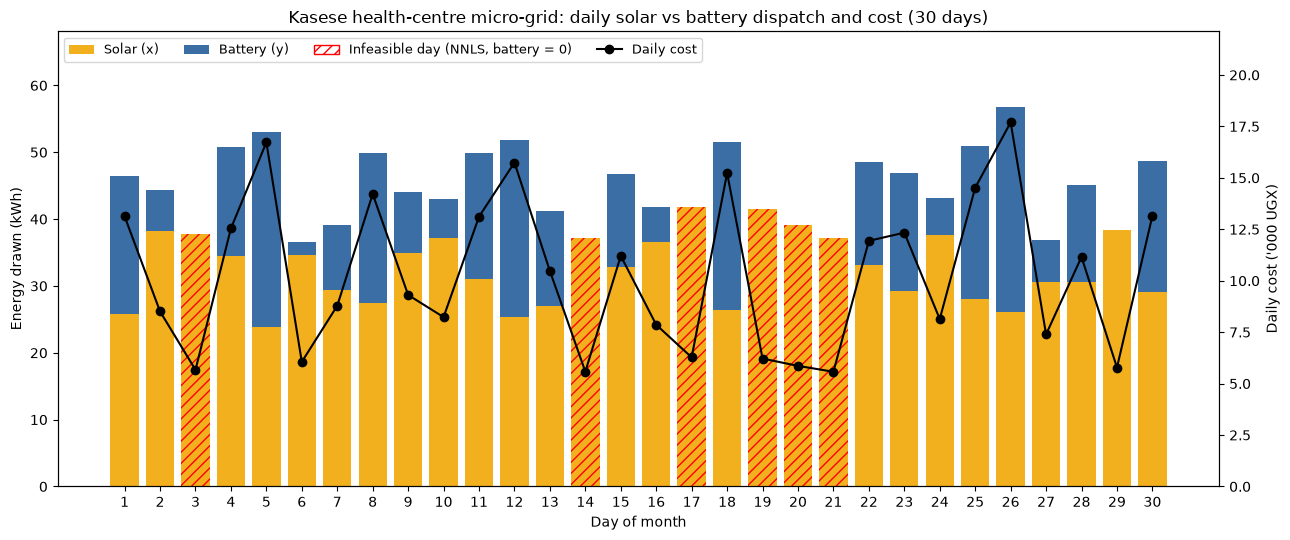

In [12]:
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(days, result.energy[0], color="#f2b01e", label="Solar (x)")
ax.bar(days, result.energy[1], bottom=result.energy[0], color="#3a6ea5", label="Battery (y)")
for d in days[result.infeasible]:
    ax.bar(d, result.energy[0, d - 1], fill=False, hatch="///", edgecolor="red", lw=0)
ax.set_xlabel("Day of month")
ax.set_ylabel("Energy drawn (kWh)")
ax.set_xticks(days)
ax.set_ylim(0, result.energy.sum(axis=0).max() * 1.2)   # headroom for the legend

ax2 = ax.twinx()
ax2.plot(days, daily_cost / 1000, "o-", color="black", lw=1.5, label="Daily cost")
ax2.set_ylabel("Daily cost ('000 UGX)")
ax2.set_ylim(0, daily_cost.max() / 1000 * 1.25)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
from matplotlib.patches import Patch
h1.append(Patch(fill=False, hatch="///", edgecolor="red")); l1.append("Infeasible day (NNLS, battery = 0)")
ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=4, fontsize=9)
ax.set_title("Kasese health-centre micro-grid: daily solar vs battery dispatch and cost (30 days)")
fig.tight_layout()
fig.savefig("figures/p2_dispatch_cost.png", dpi=150)
plt.show()

The chart shows the Task 5 point: solar forms a stable base, and almost all day-to-day movement in both energy and cost comes from the battery. Days with a large battery share are the expensive days, because battery energy costs 3× as much per kWh. The cheapest days (hatched) are **not** good news: they are the infeasible days, where the batteries were switched off and part of the load went unmet.

## Extension 1 — `HybridMicroGrid`: adding a diesel generator ($z$)

`HybridMicroGrid` **inherits** everything from `MicroGrid` (diagnostics, vectorised solving, NNLS repair, costs) and only changes the default matrix. Our third constraint is a **night-time load** that solar cannot serve:

$$3x + 2y + z = D_1,\quad 4x + y + 2z = D_2,\quad y + 3z = D_3$$

In [13]:
hybrid = HybridMicroGrid()
print(hybrid)
print(hybrid.diagnostics())

rng = np.random.default_rng(SEED)
d3 = (60 + rng.normal(0, 5, demand.shape[1])).round(1)                 # night load ~60 kWh
# Diesel now also contributes to D1 and D2, so scale those loads up a little for a realistic mix
demand3 = np.vstack([demand[0] + 40, demand[1] + 60, d3])
hyb = hybrid.dispatch(demand3)
hyb_tariff = Tariff({"solar": 150.0, "battery": 450.0, "diesel": 1200.0})   # diesel price illustrative
print(f"Infeasible days: {hyb.infeasible.sum()}")
pd.DataFrame(hyb.energy.T, columns=hybrid.sources, index=pd.Index(days, name="Day")).describe().loc[["mean", "std", "min", "max"]]

HybridMicroGrid(sources=('solar', 'battery', 'diesel'), A=[[3.0, 2.0, 1.0], [4.0, 1.0, 2.0], [0.0, 1.0, 3.0]])
{'determinant': -17.0, 'condition_number': 5.811615701214501, 'rank': 3, 'well_posed': True}
Infeasible days: 4


,solar,battery,diesel
mean,39.67,13.57,15.51
std,4.16,9.69,2.48
min,33.19,0.00,11.18
max,47.71,31.62,19.56


In [14]:
# What if the new equation is linearly dependent on the others? (row 3 = row 1 + row 2)
dependent = HybridMicroGrid(coefficients=[[3, 2, 1], [4, 1, 2], [7, 3, 3]])
print("det =", round(dependent.determinant(), 12), "| rank =", dependent.rank(), "| cond =", f"{dependent.condition_number():.2e}")
try:
    dependent.solve_day(150, 170, 320)
except np.linalg.LinAlgError as err:
    print("LinAlgError:", err)

# Consistent right-hand side (D3 = D1 + D2): infinitely many solutions -- lstsq returns just one of them
sol, *_ = np.linalg.lstsq(dependent.A, [150, 170, 320], rcond=None)
print("One of infinitely many solutions (min-norm):", sol.round(2), "-> residual", np.round(dependent.A @ sol - [150, 170, 320], 10))
# Inconsistent right-hand side (D3 != D1 + D2): no exact solution at all
sol2, res2, *_ = np.linalg.lstsq(dependent.A, [150, 170, 300], rcond=None)
print("Inconsistent case, best compromise:", sol2.round(2), "| remaining gap (kWh):", round(float(np.linalg.norm(dependent.A @ sol2 - [150, 170, 300])), 2))

det = 0.0 | rank = 2 | cond = 2.48e+16
LinAlgError: Coefficient matrix is singular: the equations are linearly dependent, so there is no unique dispatch.
One of infinitely many solutions (min-norm): [31.84 22.11 10.26] -> residual [-0. -0. -0.]
Inconsistent case, best compromise: [30.61 20.7  10.09] | remaining gap (kWh): 11.55


**Discussion.** If the third equation is a combination of the other two, it adds **no new information**. The matrix has rank 2, $\det A = 0$ and $\kappa = \infty$ (shown as about $10^{16}$ due to rounding). Two outcomes are possible:
- If the demands are *consistent* ($D_3 = D_1 + D_2$), there are **infinitely many** dispatches: we can trade diesel against solar/battery along a line of solutions. We would need an extra criterion, such as minimum cost (a linear-programming problem), to pick one.
- If they are *inconsistent*, there is **no** exact solution; least squares only gives a compromise.

In both cases `solve` must refuse, and our class raises a clear `LinAlgError` rather than returning numerical garbage.

## Extension 2 — Monte Carlo sensitivity (±5 % on $D_1$, $D_2$; 1,000 draws)

In [15]:
base = demand.mean(axis=1)                    # a typical day
mc = grid.monte_carlo_sensitivity(base, rel_perturbation=0.05, n_draws=1000, seed=SEED)
x_draws, y_draws = mc["solution_draws"]
bx, by = mc["base_solution"]
sens = pd.DataFrame({
    "base (kWh)": [bx, by],
    "std of draws (kWh)": [x_draws.std(ddof=1), y_draws.std(ddof=1)],
    "5th pct": [np.percentile(x_draws, 5), np.percentile(y_draws, 5)],
    "95th pct": [np.percentile(x_draws, 95), np.percentile(y_draws, 95)],
    "max relative move": [np.abs(x_draws / bx - 1).max(), np.abs(y_draws / by - 1).max()],
    "share of draws < 0": [(x_draws < 0).mean(), (y_draws < 0).mean()],
}, index=["solar x", "battery y"])
display(sens)
print(f"Worst observed amplification ||Δx||/||x|| ÷ ||Δd||/||d|| = {mc['amplification'].max():.2f}  (bound: κ = {grid.condition_number():.2f})")

,base (kWh),std of draws (kWh),5th pct,95th pct,max relative move,share of draws < 0
solar x,33.31,1.82,30.30,36.10,0.12,0.00
battery y,10.53,3.75,4.70,17.15,0.86,0.00


Worst observed amplification ||Δx||/||x|| ÷ ||Δd||/||d|| = 5.81  (bound: κ = 5.83)


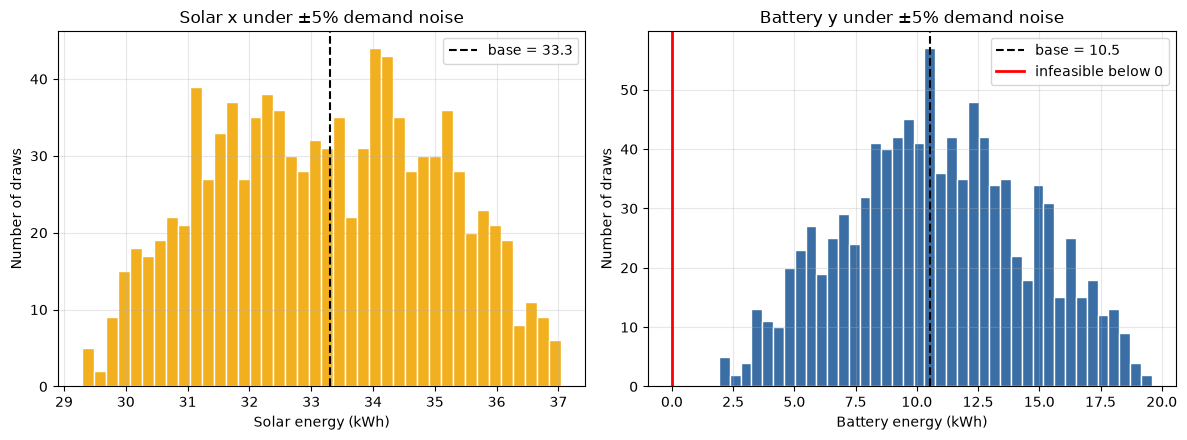

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(x_draws, bins=40, color="#f2b01e", edgecolor="white")
axes[0].axvline(bx, color="black", ls="--", label=f"base = {bx:.1f}")
axes[0].set(title="Solar x under ±5% demand noise", xlabel="Solar energy (kWh)", ylabel="Number of draws")
axes[1].hist(y_draws, bins=40, color="#3a6ea5", edgecolor="white")
axes[1].axvline(by, color="black", ls="--", label=f"base = {by:.1f}")
axes[1].axvline(0, color="red", lw=2, label="infeasible below 0")
axes[1].set(title="Battery y under ±5% demand noise", xlabel="Battery energy (kWh)", ylabel="Number of draws")
for a in axes: a.legend(); a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/p2_sensitivity.png", dpi=150); plt.show()

**Relating this to the condition number.** The overall amplification of relative error (vector norms) never exceeds $\kappa \approx 5.83$, and the worst observed value is below that bound, as the theory predicts. **Component by component**, though, the battery moves much more than 5.8 × 5 % in relative terms. This is because its base value is small compared with the demands: a ±5 % change in $D_1$ or $D_2$ is several kWh, which is a large fraction of a battery draw of about 12 kWh. So a well-conditioned system can still have one fragile variable. For a typical day no draw became infeasible, but days that are already close to the boundary (like day 19, where $D_2/D_1 = 1.34$) can be flipped from feasible to infeasible by a demand error of 1–2 %. The planner should keep a safety margin rather than dispatching exactly to the equations.

## Findings & Limitations

**Findings.** The system is mathematically sound: $\det A = -5$ and $\kappa \approx 5.8$ mean every day has one unique dispatch, and measurement errors are amplified by at most about 6×. It is **not always physically sound**, though. A day is feasible only when the critical load lies between 0.5× and 1.33× the daytime load. In our month, 6 of 30 days broke the upper limit, and the exact solution asked the batteries to *absorb* energy. NNLS repair gives the closest valid dispatch and leaves 0.5–23 kWh of unmet demand, half the gap that naïve clipping leaves. For a health centre, these days mean shedding non-critical load or a backup source, which is what the diesel extension provides. Solar is the stable, cheap base (mean 33 kWh, CV 0.16). The **battery is the volatile, expensive swing source** (CV 0.83): it supplies 27 % of energy but over half of the UGX ~308,000 monthly bill. Reducing battery dependence, e.g. by shifting flexible loads into sunlight hours, is the main cost lever.

**Limitations.** (1) The two equations are a stylised model: real micro-grids have capacity limits, battery state-of-charge that carries over between days, and solar output that depends on weather. None of these are modelled, so our "feasible" days may still be impossible on a cloudy day. (2) Demand is synthetic, so the 6/30 infeasibility rate says more about our generator's noise level than about Kasese. (3) Prices are illustrative and exclude battery degradation and capital costs. (4) NNLS minimises total squared shortfall and treats both loads as equally important. A real operator would weight the critical-equipment load much more heavily, e.g. weighted least squares or a linear programme with $D_2$ as a hard constraint.